# #30DayMapChallenge — Day 10: "Prompting only"

Where in the UK do neighbouring small areas look most *unlike* each other from space? This notebook measures dissimilarity between contiguous LSOAs (and their Scottish/NI equivalents) using the distance between their 2024 AlphaEarth satellite-embedding vectors, aggregated by [Imago](https://data.imago.ac.uk/datasets/google-satellite-embedding-v1-small-areas-2017-2024).


## Setup

The libraries used throughout: `geopandas` for the polygons and embeddings, `libpysal`'s new `Graph` for contiguity, `scikit-learn` for cosine distances, and `joblib` to compute them in parallel. `autoreload` picks up edits to the shared `gdsl30dmc_tools.py` module without restarting the kernel.


In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from libpysal import graph
from sklearn.metrics.pairwise import paired_cosine_distances

print(gpd.__version__)


1.2.0


## Reading data

Imago ships one GeoPackage per year, each holding small-area polygons (British National Grid, EPSG:27700) alongside the mean of each of the 64 embedding bands within the area. We start with 2024 and split the attributes into an embedding matrix for later distance calculations.

In [2]:
YEAR = 2024
lsoas = gpd.read_file(f"data/extracted-lsoa-geopackage_{YEAR}_output.gpkg")
band_cols = [c for c in lsoas.columns if c.startswith("band")]
lsoas = lsoas.set_index("data_zone_code")

print(lsoas.crs, lsoas.shape)
lsoas.index.str[0].value_counts().rename({"E": "England", "W": "Wales", "S": "Scotland", "N": "N. Ireland"})

ERROR 1: PROJ: proj_create_from_database: Open of /opt/conda/envs/gds/share/proj failed


EPSG:27700 (46844, 65)


data_zone_code
England       33755
Scotland       7392
N. Ireland     3780
Wales          1917
Name: count, dtype: int64

In [3]:
emb = lsoas[band_cols].to_numpy()
norms = np.linalg.norm(emb, axis=1)
print("NaN rows:", np.isnan(emb).any(axis=1).sum())
pd.Series(norms).describe()

NaN rows: 0


count    46844.000000
mean         0.910100
std          0.034245
min          0.747833
25%          0.885152
50%          0.911380
75%          0.937016
max          0.992520
dtype: float64

## Building the contiguity graph

We connect areas that share at least one boundary point (queen contiguity) using the new `libpysal.graph.Graph` API, keeping all four nations. Since the polygons come from four national statistical agencies, we first try the standard builder and check how many links cross national borders, where boundaries may not line up.


In [4]:
%%time
g_queen = graph.Graph.build_contiguity(lsoas, rook=False)
g_queen.summary()


CPU times: user 15.8 s, sys: 816 ms, total: 16.6 s
Wall time: 16.6 s


Graph Summary Statistics
========================
Graph indexed by:
 ['E01000001', 'E01000002', 'E01000003', 'E01000005', 'E01...]
==============================================================
Number of nodes:                                         46844
Number of edges:                                        272424
Number of connected components:                             32
Number of isolates:                                         12
Number of non-zero edges:                               272424
Percentage of non-zero edges:                            0.01%
Number of asymmetries:                            NA
--------------------------------------------------------------
Cardinalities
==============================================================
Mean:                       6    25%:                        4
Standard deviation:         2    50%:                        6
Min:                        0    75%:                        7
Max:                       53
--------------------------------------------------------------
Weights
==============================================================
Mean:                       1    25%:                        1
Standard deviation:         0    50%:                        1
Min:                        1    75%:                        1
Max:                        1
--------------------------------------------------------------
Sum of weights
==============================================================
S0:                                                     272424
S1:                                                     544848
S2:                                                    7348832
--------------------------------------------------------------
Traces
==============================================================
GG:                                                     272424
G'G:                                                    272424
G'G + GG:                                               544848

In [5]:
nation = pd.Series(lsoas.index.str[0], index=lsoas.index)

def link_types(g):
    """Count directed links by nation pair, ignoring isolates' zero-weight self-loops."""
    adj = g.adjacency.reset_index()
    adj = adj[adj.focal != adj.neighbor]
    return pd.Series(nation.loc[adj.focal].values + "-" + nation.loc[adj.neighbor].values).value_counts()

link_types(g_queen)


E-E    197754
S-S     41688
N-N     22164
W-W     10616
W-E        99
E-W        99
E-S         2
S-E         2
Name: count, dtype: int64

### Fixing the England–Scotland border

Only one England–Scotland pair is linked, even though about two dozen pairs of areas meet along that border. The two nations' polygons slightly *overlap* there (by up to ~70,000 m²), and contiguity only counts polygons that touch without overlapping. Fuzzy contiguity links any pair of geometries that intersect, which covers touching (queen) and overlapping polygons alike, so it fixes the border without adding spurious links elsewhere.

In [6]:
%%time
g = graph.Graph.build_fuzzy_contiguity(lsoas)

edges = lambda g: set(g.adjacency[g.adjacency > 0].index)
print("Links only in queen:", len(edges(g_queen) - edges(g)), "| only in fuzzy:", len(edges(g) - edges(g_queen)))
link_types(g)

Links only in queen: 0 | only in fuzzy: 42
CPU times: user 3.38 s, sys: 32.1 ms, total: 3.41 s
Wall time: 3.41 s


E-E    197754
S-S     41688
N-N     22164
W-W     10616
W-E        99
E-W        99
E-S        23
S-E        23
Name: count, dtype: int64

In [7]:
print("Isolates:", len(g.isolates), "| Components:", g.n_components)
print(pd.Series(g.component_labels).value_counts().head(5))
g.cardinalities.describe()


Isolates: 12 | Components: 31
component labels
0     42777
29     3779
1        89
4        41
12       28
Name: count, dtype: int64


count    46844.000000
mean         5.816455
std          2.323981
min          0.000000
25%          4.000000
50%          6.000000
75%          7.000000
max         53.000000
Name: cardinalities, dtype: float64

### Dropping areas with no neighbours

**Note:** the 12 areas with no neighbours (their own islands, with no link to any other area) are **removed from both the graph and the embeddings table** at this point, because a neighbour-dissimilarity score is undefined without neighbours. Island groups made up of several areas (e.g. in the Hebrides or Orkney) are kept, since their areas still neighbour each other. Everything below works on the trimmed `g`, `lsoas` and `emb`.

The figure below records which areas were dropped, before we remove them: all 12 are offshore islands (Scilly, the Inner Hebrides, Orkney, Shetland and Rathlin), not mainland areas the graph wrongly failed to link.


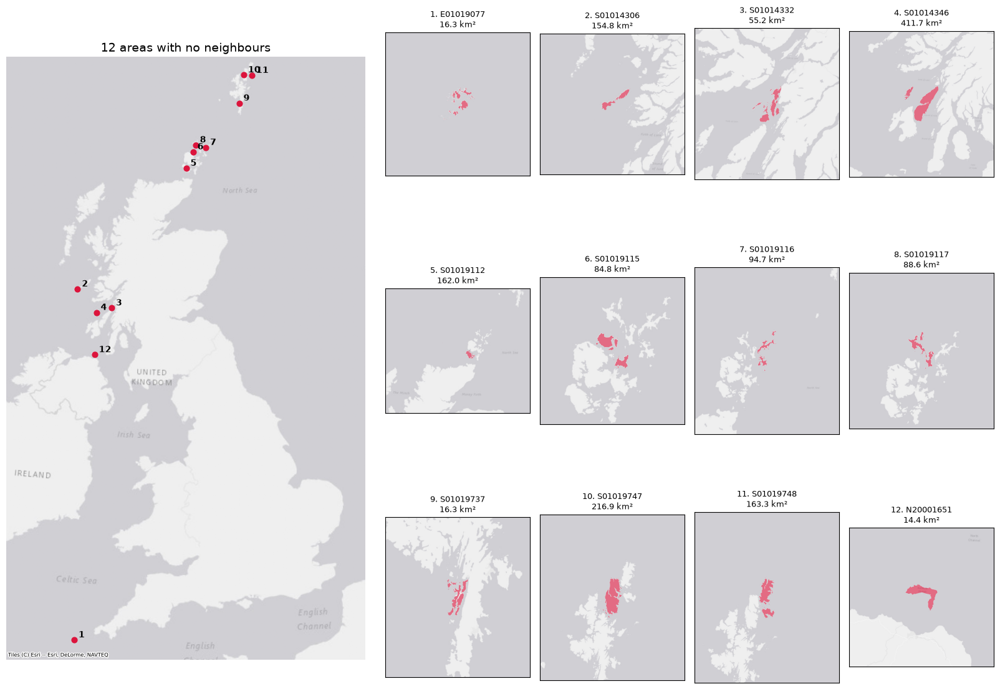

In [8]:
import contextily as cx

isolates = g.isolates
iso = lsoas.loc[isolates, ["geometry"]]
tiles = cx.providers.Esri.WorldGrayCanvas  # light, keyless basemap

fig = plt.figure(figsize=(16, 12))
ax0 = fig.add_axes([0, 0, 0.36, 1])
pts = iso.representative_point()
pts.plot(ax=ax0, color="crimson", markersize=40, zorder=3)
for i, p in enumerate(pts, 1):
    ax0.annotate(str(i), (p.x, p.y), xytext=(5, 3), textcoords="offset points", fontsize=10, weight="bold")
ax0.set_xlim(-50_000, 700_000)
ax0.set_ylim(-30_000, 1_230_000)
cx.add_basemap(ax0, crs=iso.crs, source=tiles, attribution_size=6)
ax0.set_axis_off()
ax0.set_title(f"{len(isolates)} areas with no neighbours", fontsize=14)

for i, code in enumerate(isolates):
    ax = fig.add_axes([0.38 + (i % 4) * 0.155, 0.70 - (i // 4) * 0.33, 0.145, 0.28])
    area = iso.loc[[code]]
    x0, y0, x1, y1 = area.total_bounds
    pad = max(x1 - x0, y1 - y0) * 1.5 + 2000
    area.plot(ax=ax, color="crimson", alpha=0.6)
    ax.set_xlim(x0 - pad, x1 + pad)
    ax.set_ylim(y0 - pad, y1 + pad)
    cx.add_basemap(ax, crs=iso.crs, source=tiles, attribution=False)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_xlabel(""); ax.set_ylabel("")
    ax.set_title(f"{i + 1}. {code}\n{area.area.iloc[0] / 1e6:.1f} km²", fontsize=9)



In [9]:
isolates = g.isolates
print(f"Dropping {len(isolates)} areas:", ", ".join(isolates))

lsoas = lsoas.drop(isolates)
g = g.subgraph(lsoas.index)
emb = lsoas[band_cols].to_numpy()

assert (g.unique_ids == lsoas.index).all() and len(g.isolates) == 0
print(f"Remaining: {len(lsoas):,} areas | {g.n_edges:,} links | {g.n_components} components")

Dropping 12 areas: E01019077, S01014306, S01014332, S01014346, S01019112, S01019115, S01019116, S01019117, S01019737, S01019747, S01019748, N20001651
Remaining: 46,832 areas | 272,466 links | 19 components


## Neighbour dissimilarity

We measure how different each area is from each of its neighbours using **cosine distance** between their 2024 embedding vectors (1 − cosine similarity, from 0 for identical directions to 2 for opposite). Cosine ignores vector length, which in these area averages partly reflects how mixed the land cover is, and is the comparison AlphaEarth embeddings are designed for. Neighbours come from the fuzzy-contiguity graph `g`, i.e. queen contiguity plus the overlapping England–Scotland border pairs.

The 46,832 areas are split into 16 groups (one per core), and each group's distances to all its neighbours are computed on a separate thread. NumPy releases Python's global interpreter lock while it computes, so threads share the arrays without copying them. The results are reassembled into the order of `g.adjacency` and stored as the weights of a new graph, `g_dist`.

In [10]:
%%time
N_CHUNKS = 16
emb = np.ascontiguousarray(emb)  # row-major, so gathering whole rows is fast (~4x here)

adj = g.adjacency
i = lsoas.index.get_indexer(adj.index.get_level_values("focal"))  # row of each focal area in emb
j = lsoas.index.get_indexer(adj.index.get_level_values("neighbor"))

# Assign each area to one of N_CHUNKS groups, then find the links whose focal area is in each group
area_chunk = np.repeat(np.arange(N_CHUNKS), [len(c) for c in np.array_split(np.arange(len(lsoas)), N_CHUNKS)])
link_chunk = area_chunk[i]
rows = [np.flatnonzero(link_chunk == k) for k in range(N_CHUNKS)]

parts = Parallel(n_jobs=N_CHUNKS, backend="threading")(
    delayed(paired_cosine_distances)(emb[i[r]], emb[j[r]]) for r in rows
)
dist = np.empty(len(adj))
for r, d in zip(rows, parts):
    dist[r] = d

g_dist = graph.Graph(pd.Series(dist, index=adj.index, name="weight"))



CPU times: user 1.12 s, sys: 271 ms, total: 1.39 s
Wall time: 865 ms


In [11]:
# Sanity checks: every link covered once, identical to the serial calculation, same structure as g
assert sum(len(r) for r in rows) == len(adj)
assert np.allclose(dist, paired_cosine_distances(emb[i], emb[j]))
assert g_dist.n_edges == g.n_edges and (g_dist.unique_ids == g.unique_ids).all()

g_dist.adjacency.describe()

count    272466.000000
mean          0.053723
std           0.058251
min           0.000446
25%           0.015623
50%           0.032057
75%           0.068060
max           0.538219
Name: weight, dtype: float64

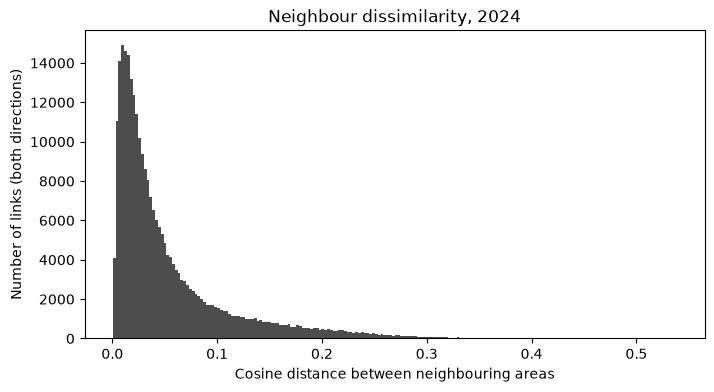

In [12]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(g_dist.adjacency, bins=200, color="0.3")
ax.set_xlabel("Cosine distance between neighbouring areas")
ax.set_ylabel("Number of links (both directions)")
ax.set_title(f"Neighbour dissimilarity, {YEAR}");

### Most dissimilar neighbour

For each area we keep the single neighbour it differs from most, and the cosine distance to it. The result is a table with one row per area, indexed by area code, with two columns: `neighbor` (the most dissimilar neighbour's code) and `distance`.

In [13]:
d = g_dist.adjacency
most_dissimilar = (
    d.sort_values(ascending=False)
    .reset_index()
    .drop_duplicates("focal")  # keeps each area's largest distance
    .set_index("focal")
    .reindex(lsoas.index)
    .rename(columns={"weight": "distance"})
)
most_dissimilar.index.name = "area"

assert most_dissimilar.notna().all().all()
most_dissimilar.sort_values("distance", ascending=False).head(10)

,neighbor,distance
area,,
E01030710,E01030745,0.538219
E01030745,E01030710,0.538219
E01030744,E01030745,0.535450
E01030746,E01030745,0.533737
E01030711,E01030745,0.524066
E01031353,E01031359,0.513233
E01031359,E01031353,0.513233
E01034298,E01020936,0.502896
E01020936,E01034298,0.502896


In [14]:
most_dissimilar["distance"].describe()

count    46832.000000
mean         0.116488
std          0.076095
min          0.001527
25%          0.056489
50%          0.099182
75%          0.162252
max          0.538219
Name: distance, dtype: float64

### Dissimilarity from the whole neighbourhood

Two ways to score how different an area is from its neighbourhood as a whole, using equal weights for every neighbour:

- **`mean_dist`**: the average of the cosine distances to each neighbour, i.e. how different the area is from its neighbours one by one. Taken from the weights of `g_dist`.
- **`lag_dist`**: the cosine distance to the *average neighbour*, i.e. how different the area is from its surroundings taken together. The average neighbour is the spatial lag of the embeddings on the row-standardised graph.

Since averaging neighbours tends to cancel out their differences, `lag_dist` should be at most `mean_dist` for nearly every area. The gap between the two is roughly how much the neighbours differ among themselves.

In [15]:
emb_lag = g.transform("r").lag(emb)  # row i = mean embedding of area i's neighbours

neighbourhood = pd.DataFrame({
    "mean_dist": g_dist.aggregate("mean").reindex(lsoas.index),
    "lag_dist": paired_cosine_distances(emb, emb_lag),
}, index=lsoas.index)

assert neighbourhood.notna().all().all()
print("Areas where lag_dist > mean_dist:", (neighbourhood.lag_dist > neighbourhood.mean_dist).sum())
print("Spearman rank correlation:", round(neighbourhood.corr(method="spearman").iloc[0, 1], 3))
neighbourhood.describe()

Areas where lag_dist > mean_dist: 0
Spearman rank correlation: 0.839


,mean_dist,lag_dist
count,46832.000000,46832.000000
mean,0.053231,0.025731
std,0.033342,0.026431
min,0.001246,0.000389
25%,0.029067,0.009408
50%,0.046407,0.017330
75%,0.069374,0.032247
max,0.455714,0.438115


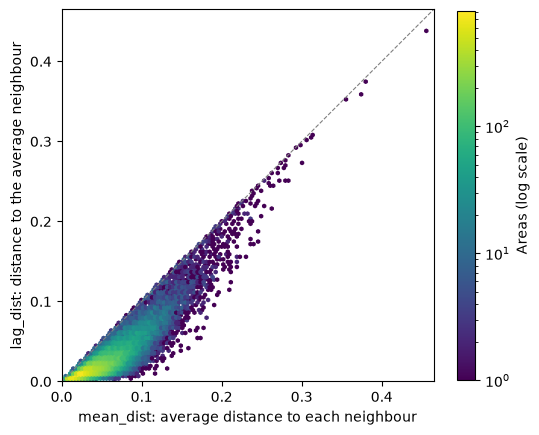

In [16]:
fig, ax = plt.subplots(figsize=(6, 6))
hb = ax.hexbin(neighbourhood.mean_dist, neighbourhood.lag_dist, gridsize=120, bins="log", cmap="viridis", mincnt=1)
lim = neighbourhood.max().max() * 1.02
ax.plot([0, lim], [0, lim], color="0.5", lw=0.8, ls="--")
ax.set_xlim(0, lim); ax.set_ylim(0, lim); ax.set_aspect("equal")
ax.set_xlabel("mean_dist: average distance to each neighbour")
ax.set_ylabel("lag_dist: distance to the average neighbour")
fig.colorbar(hb, ax=ax, shrink=0.8, label="Areas (log scale)");

## Mapping the most dissimilar areas

Each area becomes a Polaroid-style card. A square satellite photo (Esri imagery, no API key needed) shows the focal area outlined in orange and its neighbours in green, with everything outside them washed out towards white. Below it, a caption strip carries the area code and its scores in bold [Figtree](https://github.com/erikdkennedy/figtree), Imago's brand font, plus a UK silhouette locating the area. Colours follow [Imago](https://imago.ac.uk)'s brand palette: Orange `#FF8F42`, Green `#03CEA3`, and Imago Grey `#4A4A49` for the text and the UK silhouette.

The card template, the UK silhouette and the export helper live in `gdsl30dmc_tools.py`, shared with the other notebooks. The silhouette is built by merging each nation's areas, using GEOS's fast `coverage_union` where the polygons tile cleanly, then simplifying. It takes about 25 s and is cached to `data/uk_outline.parquet`, so it's only built once.


In [17]:
%%time
import gdsl30dmc_tools as tools

uk_outline = tools.uk_outline(lsoas)


CPU times: user 25.7 s, sys: 510 ms, total: 26.2 s
Wall time: 26.2 s


In [18]:
def plot_focal(code):
    """Card for area `code` (orange) and its neighbours (green), captioned with its neighbourhood scores."""
    s = neighbourhood.loc[code]
    subtitle = f"mean_dist {s.mean_dist:.3f}  ·  lag_dist {s.lag_dist:.3f}  ·  {g.cardinalities[code]} neighbours"
    return tools.area_card(lsoas, code, g.neighbors[code], subtitle, uk_outline)


def plot_pair(a, b):
    """Card for neighbouring areas `a` (orange) and `b` (green), captioned with their cosine distance."""
    subtitle = f"cosine distance {g_dist.adjacency.loc[(a, b)]:.3f}  ·  neighbouring areas"
    return tools.pair_card(lsoas, a, b, subtitle, uk_outline)


### The most dissimilar area

`E01030745` ranks first on both `mean_dist` and `lag_dist`. It is almost entirely open water, a pair of reservoir basins just south of Heathrow, surrounded by housing, industry and airport land. Its only similar neighbour (cosine distance 0.16) is the large reservoir to the west.

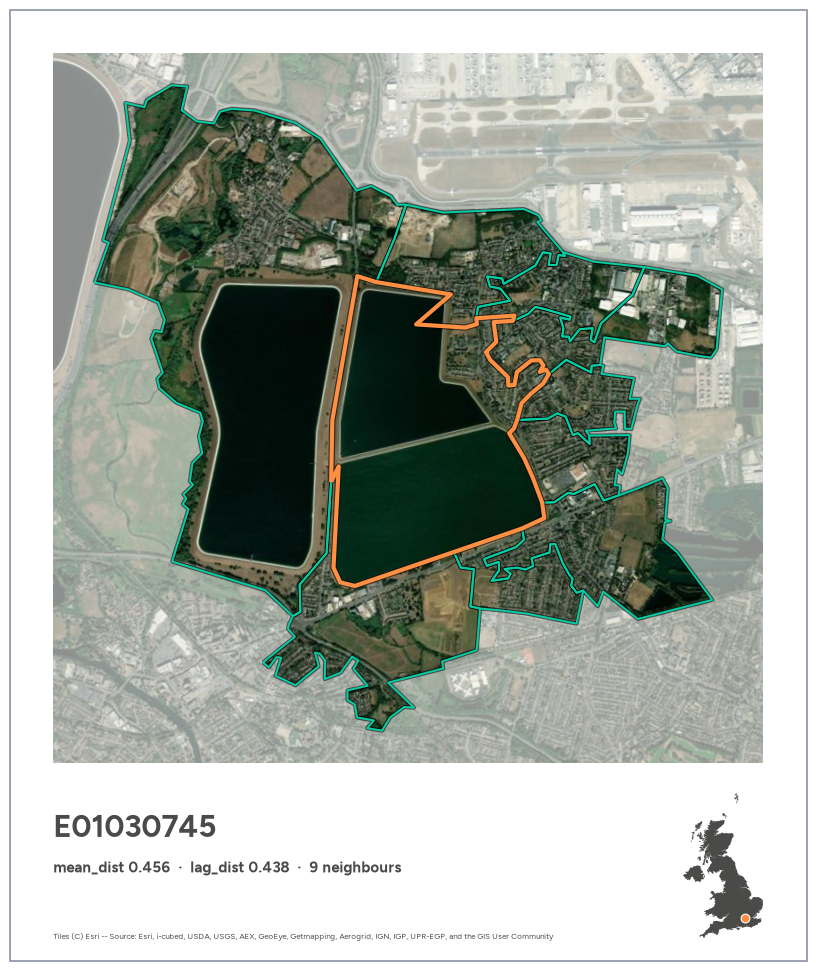

In [19]:
top = neighbourhood["lag_dist"].idxmax()
assert top == neighbourhood["mean_dist"].idxmax()
fig = plot_focal(top)


### Exporting the cards

Cards are saved to `figures/` at 200 dpi with `tools.export_card`, keeping the full white border and caption strip. It doesn't use `bbox_inches="tight"`, which would trim the Polaroid margins.


In [20]:
export_card = tools.export_card
export_card(fig, top)


PosixPath('/home/jovyan/work/figures/E01030745.png')

### Top 5 areas on each measure

We take the five highest-scoring areas on `mean_dist` and on `lag_dist`, combine them into one list without duplicates, and make and export a card for each. The table shows each area's rank on both measures.

In [21]:
N_TOP = 5
top_mean = neighbourhood["mean_dist"].nlargest(N_TOP).index
top_lag = neighbourhood["lag_dist"].nlargest(N_TOP).index
cases = top_mean.union(top_lag, sort=False)

ranks = neighbourhood.rank(ascending=False).astype(int).add_suffix("_rank")
neighbourhood.join(ranks).loc[cases]

,mean_dist,lag_dist,mean_dist_rank,lag_dist_rank
data_zone_code,,,,
E01030745,0.455714,0.438115,1,1
N20003012,0.381098,0.373842,2,2
W01001286,0.375061,0.359898,3,3
N20002748,0.355019,0.353096,4,4
E01026177,0.314997,0.307863,5,5


/home/jovyan/work/figures/E01030745.png


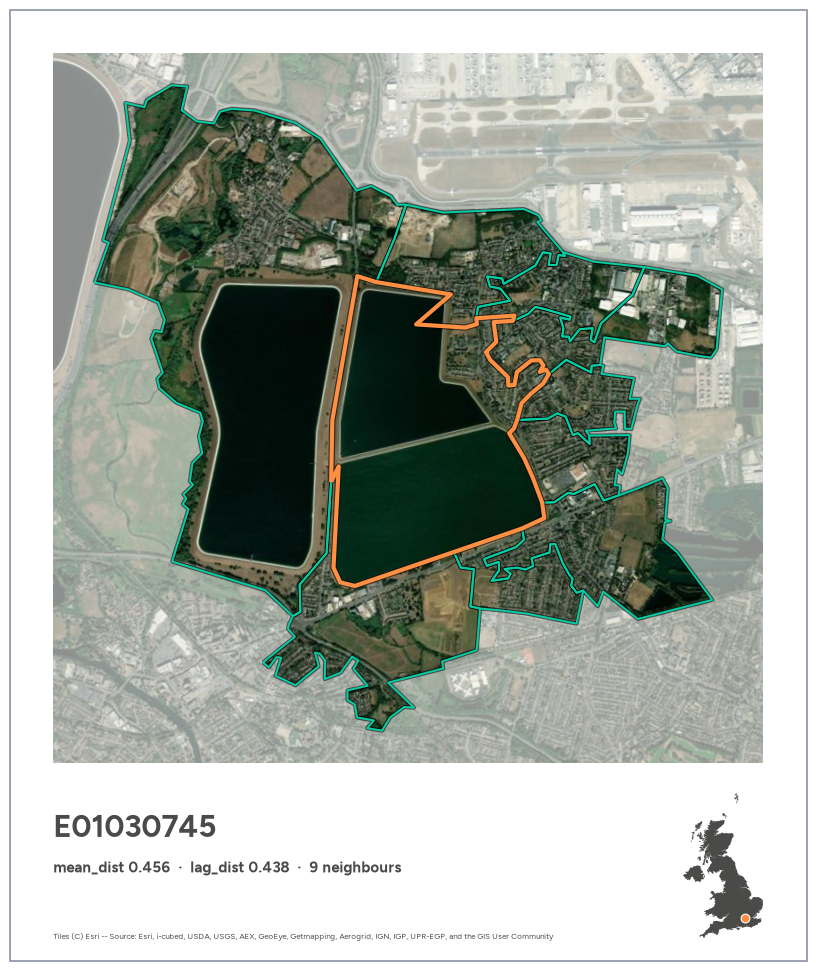

/home/jovyan/work/figures/N20003012.png


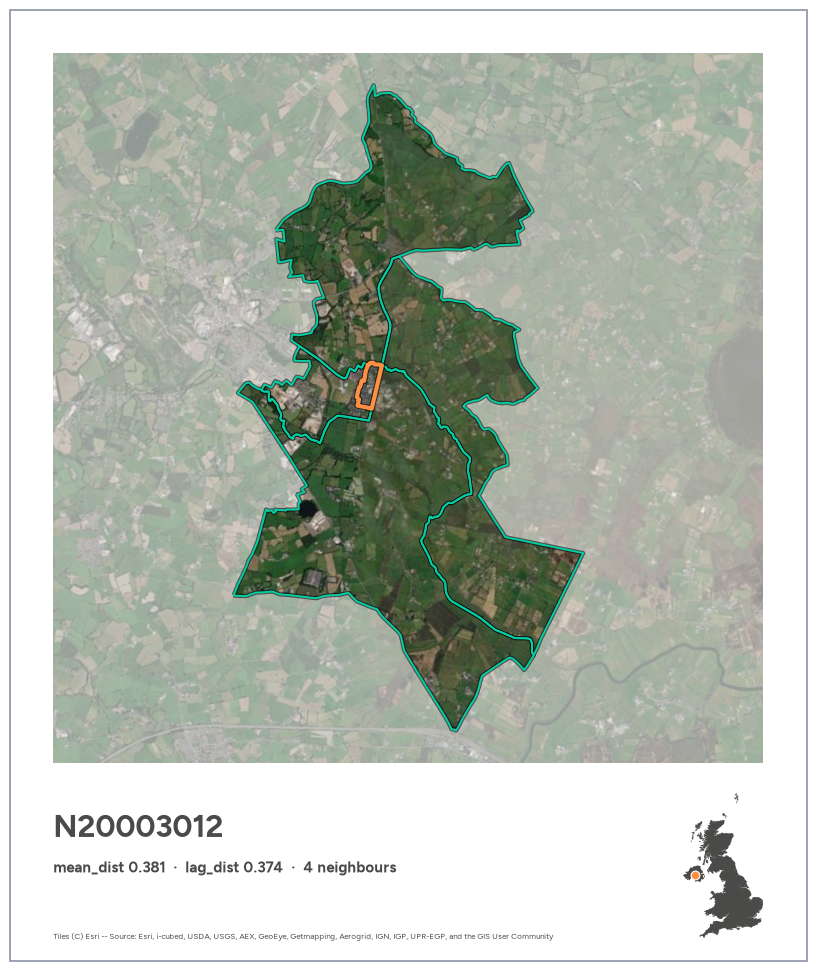

/home/jovyan/work/figures/W01001286.png


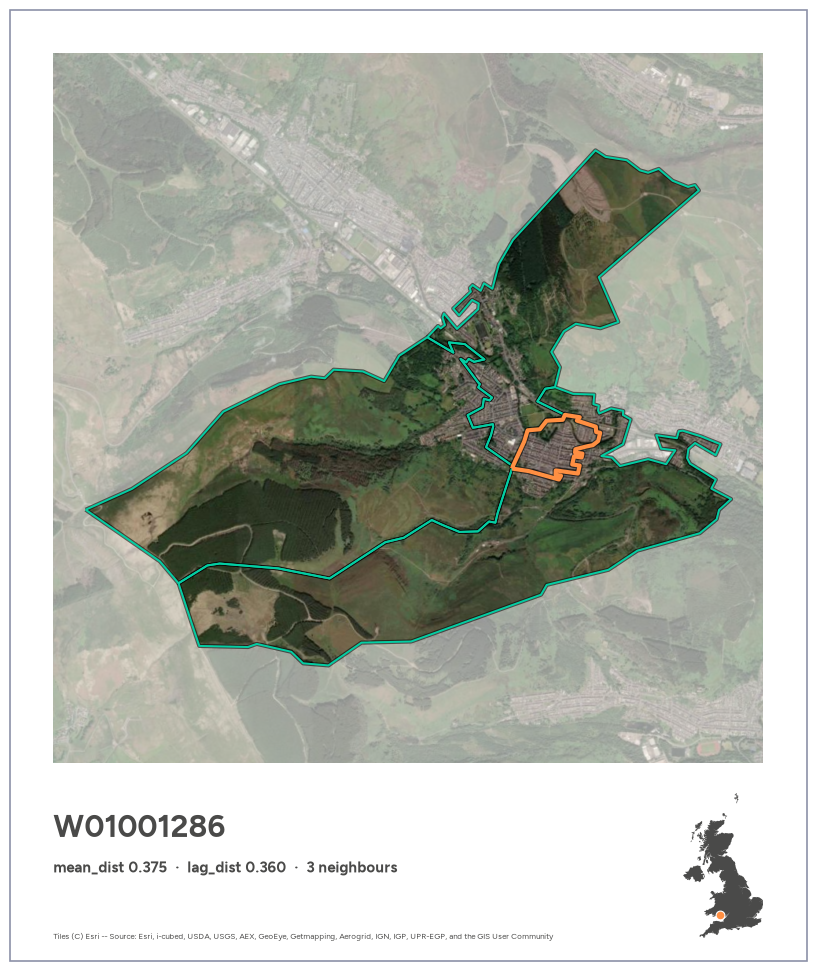

/home/jovyan/work/figures/N20002748.png


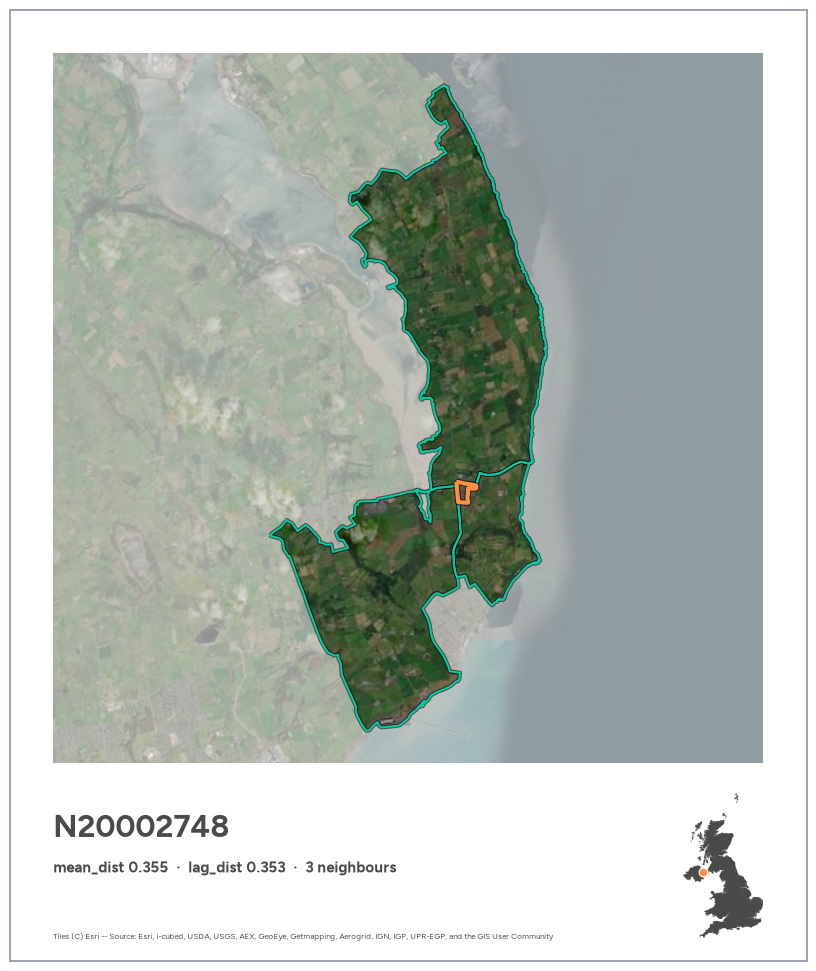

/home/jovyan/work/figures/E01026177.png


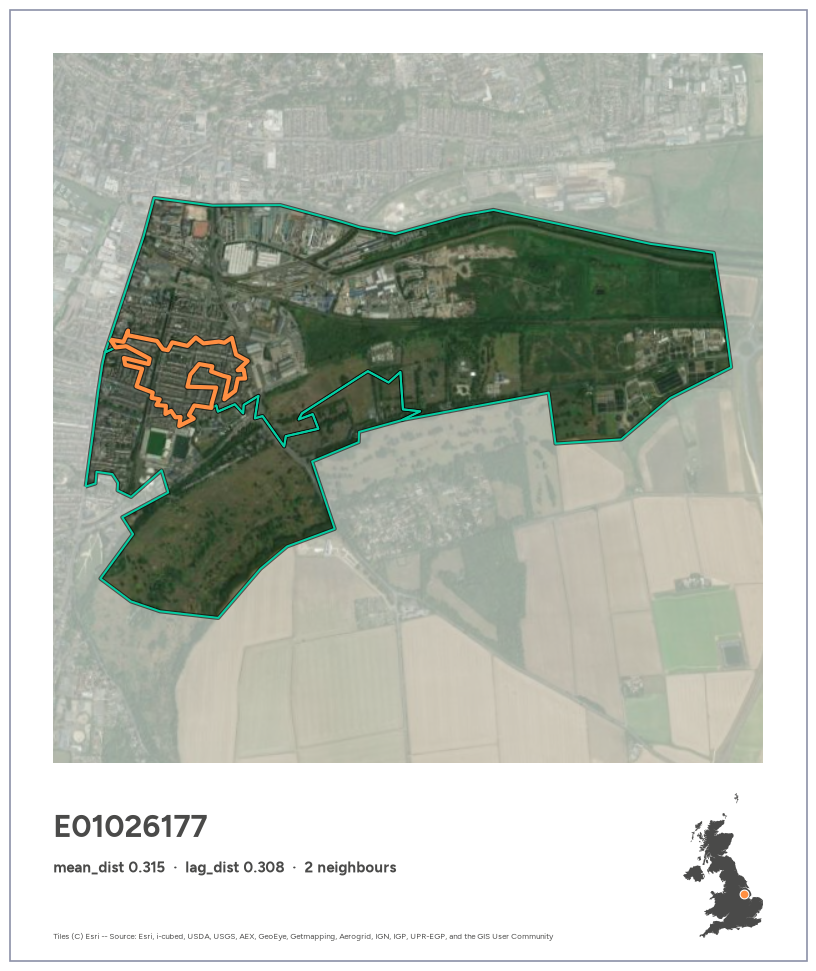

In [22]:
for code in cases:
    fig = plot_focal(code)
    print(export_card(fig, code))
    plt.show()

## Most dissimilar neighbouring pairs

Instead of scoring an area against its whole neighbourhood, we now look at individual pairs of neighbours: two areas that share a border and look most unlike each other from space. Each pair appears twice in `g_dist` (A→B and B→A, with the same distance), so we keep one row per pair and rank them by cosine distance.

In [23]:
pairs = g_dist.adjacency.reset_index().rename(columns={"focal": "area_a", "neighbor": "area_b", "weight": "distance"})
pairs = pairs[pairs.area_a < pairs.area_b].sort_values("distance", ascending=False).reset_index(drop=True)

print(f"{len(pairs):,} unique pairs")
pairs["distance"].describe()

136,233 unique pairs


count    136233.000000
mean          0.053723
std           0.058251
min           0.000446
25%           0.015623
50%           0.032057
75%           0.068060
max           0.538219
Name: distance, dtype: float64

In [24]:
top_pairs = pairs.head(20)
print("Distinct areas among the top 20 pairs:", pd.unique(top_pairs[["area_a", "area_b"]].values.ravel()).size)
print("Most frequent areas in the top 20:")
print(pd.Series(top_pairs[["area_a", "area_b"]].values.ravel()).value_counts().head(5).to_string())
top_pairs

Distinct areas among the top 20 pairs: 32
Most frequent areas in the top 20:
E01030745    7
E01034298    2
N20003012    2
E01030744    1
E01030711    1


,area_a,area_b,distance
0,E01030710,E01030745,0.538219
1,E01030744,E01030745,0.535450
2,E01030745,E01030746,0.533737
3,E01030711,E01030745,0.524066
4,E01031353,E01031359,0.513233
5,E01020936,E01034298,0.502896
6,E01030708,E01030745,0.502224
7,E01020937,E01034298,0.501605
8,E01029178,E01035125,0.483857
9,W01001947,W01002024,0.480610


### Top distinct pairs

To avoid one area filling the list, we go down the ranking and skip any pair that shares an area with a pair already chosen. Each area then appears at most once. Each selected pair gets a Polaroid card from the same template as the area cards (`polaroid()`, via `plot_pair`): area A outlined in orange, area B in green, with a matching colour key next to each code in the caption.

In [25]:
N_PAIRS = 5
used, picks = set(), []
for row in pairs.itertuples():
    if row.area_a in used or row.area_b in used:
        continue
    picks.append(row.Index)
    used |= {row.area_a, row.area_b}
    if len(picks) == N_PAIRS:
        break

top_distinct = pairs.loc[picks]
top_distinct

,area_a,area_b,distance
0,E01030710,E01030745,0.538219
4,E01031353,E01031359,0.513233
5,E01020936,E01034298,0.502896
8,E01029178,E01035125,0.483857
9,W01001947,W01002024,0.480610


/home/jovyan/work/figures/pair_E01030710_E01030745.png


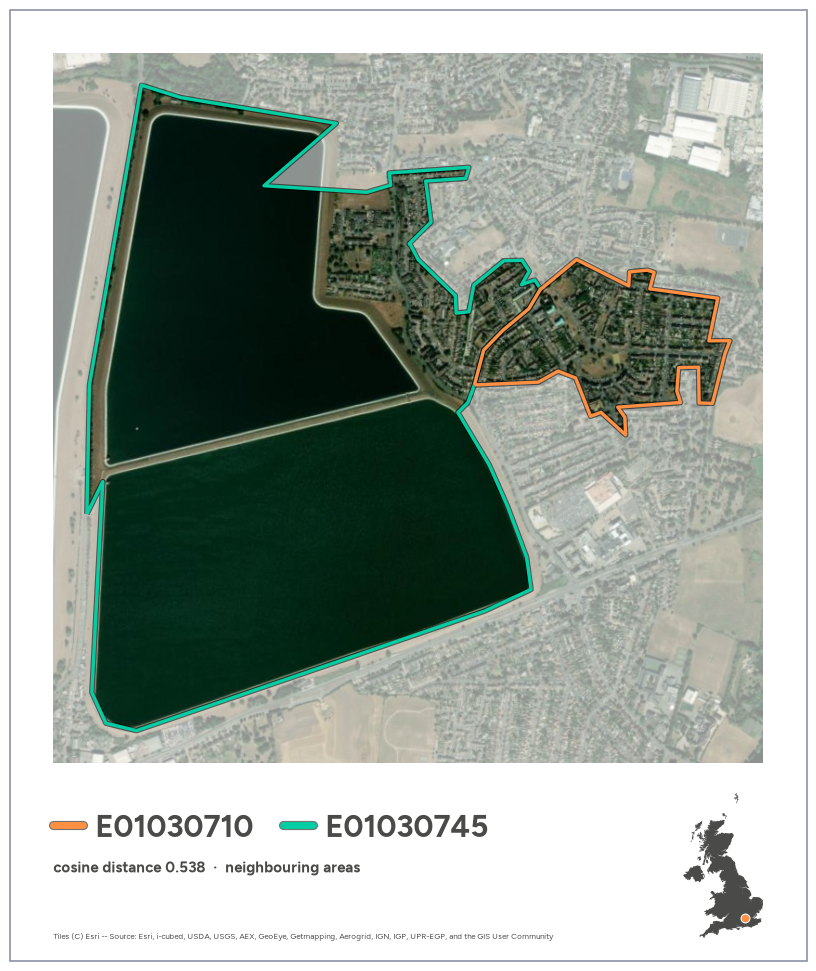

/home/jovyan/work/figures/pair_E01031353_E01031359.png


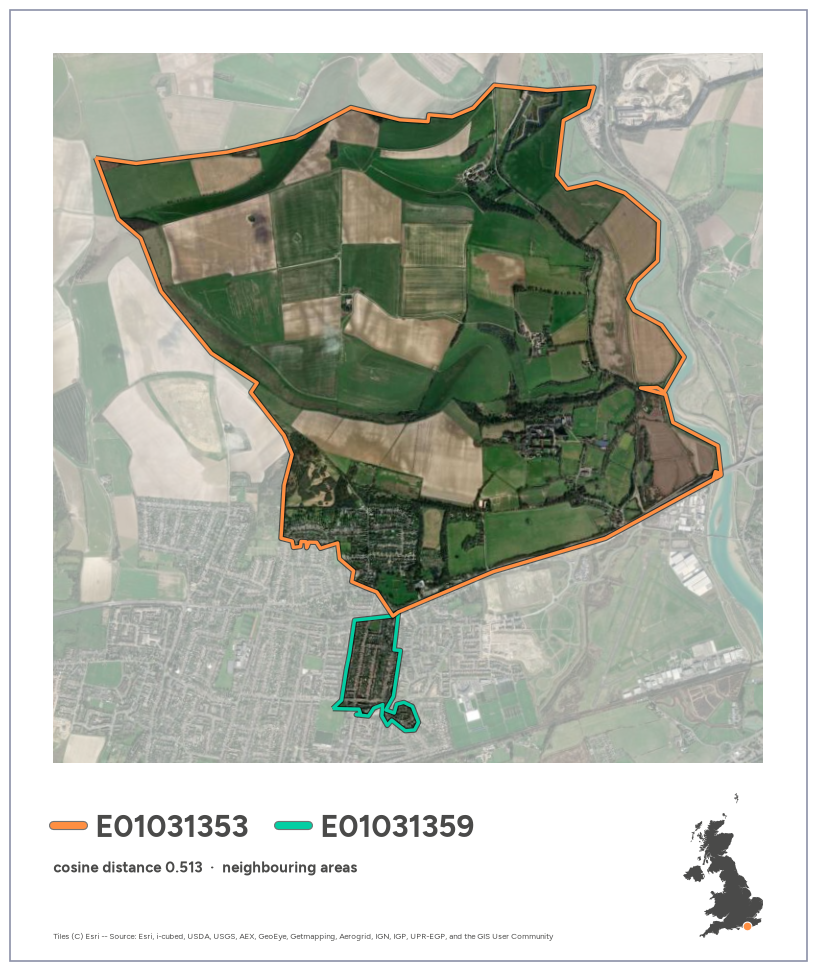

/home/jovyan/work/figures/pair_E01020936_E01034298.png


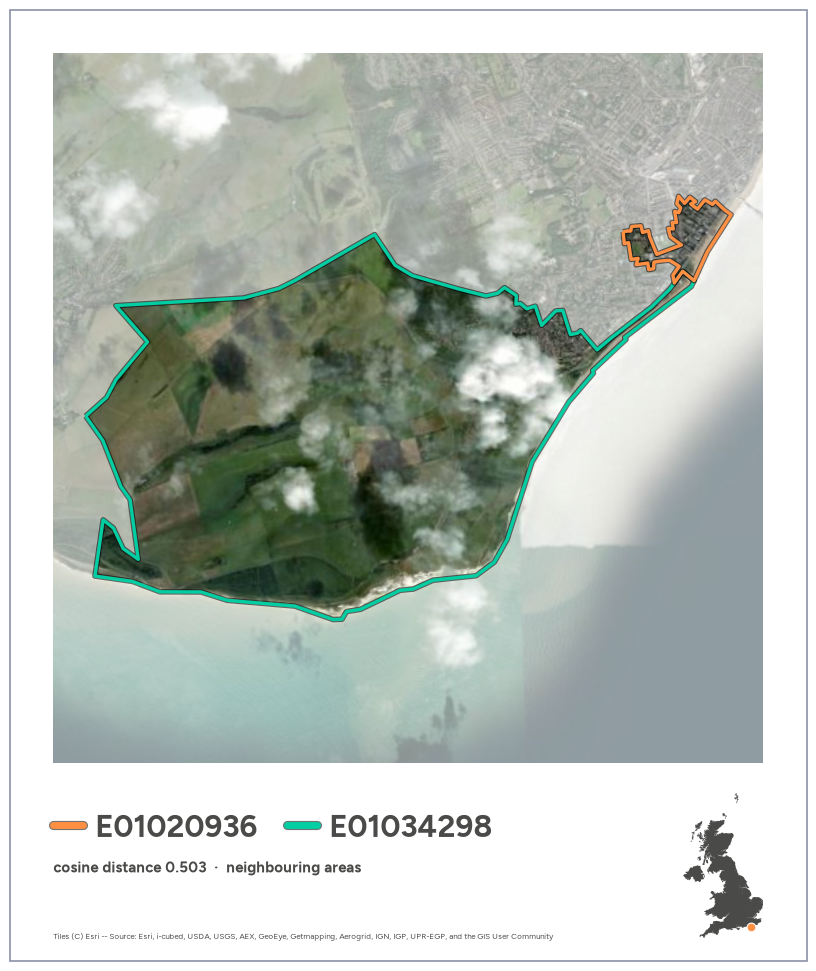

/home/jovyan/work/figures/pair_E01029178_E01035125.png


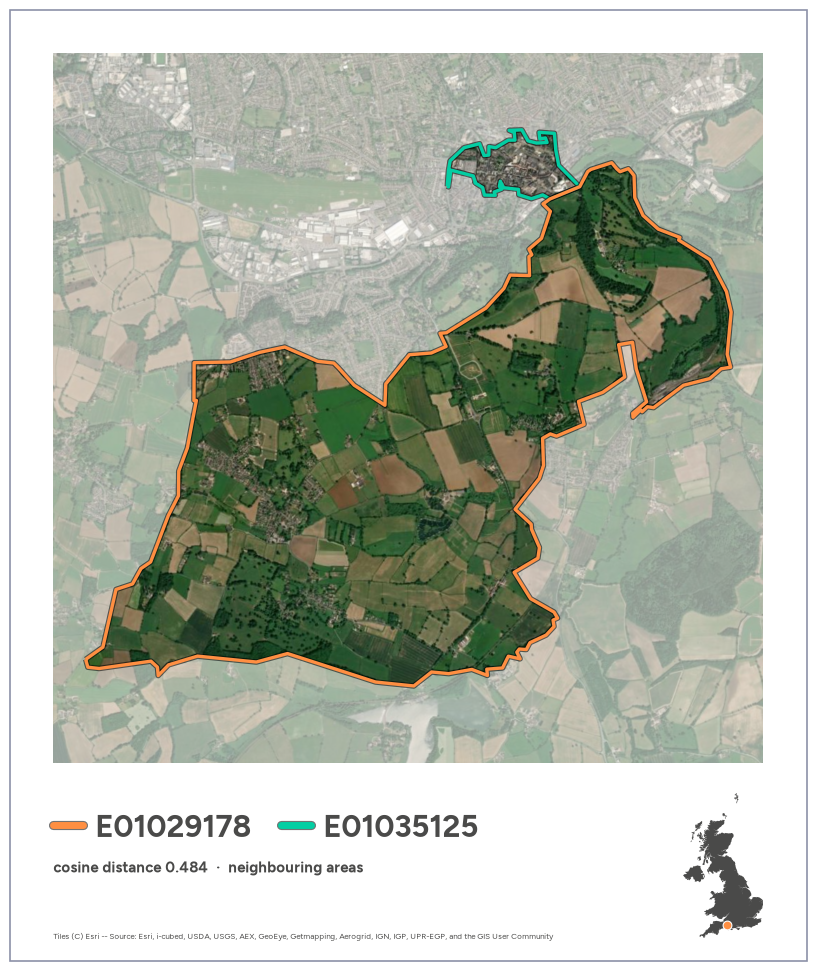

/home/jovyan/work/figures/pair_W01001947_W01002024.png


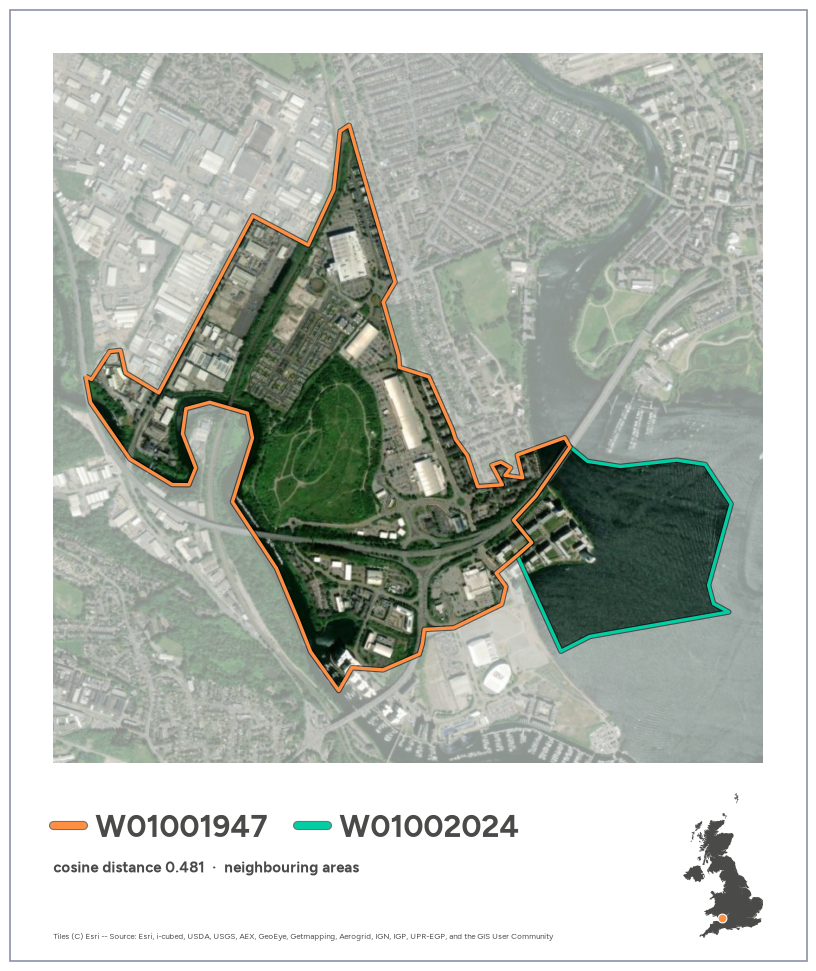

In [26]:
for row in top_distinct.itertuples():
    fig = plot_pair(row.area_a, row.area_b)
    print(export_card(fig, f"pair_{row.area_a}_{row.area_b}"))
    plt.show()